# 02 · Modelado, validación y decisión comercial
La comparación usa cuatro ventanas expansivas por calendario. Las transformaciones aprendidas se ajustan dentro de cada entrenamiento. Optuna optimiza AP media, MLflow registra experimentos. El benchmark 585–730 ya fue consultado en el prototipo y no es un test virgen.

**Reproducir:** ejecutar el comando de experimentos del README. El notebook carga resultados guardados por defecto para no repetir búsquedas al revisarlo. La celda opcional permite regenerarlos explícitamente.

In [1]:
from ferreyros_propension.plotting import apply_theme, save, style_table

apply_theme()

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

from ferreyros_propension.data import features, load_data

ROOT = Path.cwd()
if not (ROOT / "Dataset").exists():
    ROOT = ROOT.parent
OUTPUT = ROOT / "outputs"
for folder in ["tables", "figures"]:
    (OUTPUT / folder).mkdir(parents=True, exist_ok=True)
raw = load_data(ROOT / "Dataset/compras_data.csv")

import joblib
import yaml

config = yaml.safe_load((ROOT / "config.yml").read_text())
RERUN_EXPERIMENTS = False
if RERUN_EXPERIMENTS:
    from ferreyros_propension.modeling import run_experiments

    run_experiments(ROOT)

## 1. Diseño de validación y variables
Entrenar con días pasados y validar con días posteriores evita repartir visitas del mismo futuro entre train y validación. El escenario es uso secuencial en clientes conocidos: las compras ya observadas pueden actualizar la historia antes de la siguiente visita. El modelo no se reajusta con etiquetas del fold externo.

Las ventanas de 30/60/90 días se definen por calendario y excluyen el evento actual. Se usa prior fijo 0,25 con peso 4 para tasas, evitando estimarlo con datos futuros. No se incluyen ID, marca/cantidad actuales, campos ambiguos ni tamaño de ciudad. Los intervalos de visitas sin historial se imputan dentro del entrenamiento; las categorías desconocidas tienen tratamiento explícito.

La validación por días difiere de aplicar TimeSeriesSplit al orden por cliente: ese orden no representa una serie cronológica global.

In [2]:
display(
    style_table(pd.DataFrame(config["folds"], columns=["fin_train", "fin_validacion"]))
)
events, predictors = features(raw)
display(
    style_table(
        pd.DataFrame(
            {
                "variable": predictors.columns,
                "tipo": predictors.dtypes.astype(str).values,
            }
        )
    )
)
print("Variables:", predictors.shape[1])

,fin_train,fin_validacion
0,200,296
1,296,392
2,392,488
3,488,584


,variable,tipo
0,precio_marca_1,float64
1,precio_marca_2,float64
2,precio_marca_3,float64
3,precio_marca_4,float64
4,precio_marca_5,float64
5,promo_marca_1,int64
6,promo_marca_2,int64
7,promo_marca_3,int64
8,promo_marca_4,int64
9,promo_marca_5,int64


Variables: 46


### Diccionario de variables derivadas

| Grupo | Fórmula o definición | Disponibilidad |
|---|---|---|
| Visitas/compras previas | Conteos acumulados excluyendo la fila actual | Historia anterior al instante de scoring |
| Tasa previa | `(compras_previas + 1) / (visitas_previas + 4)` | Prior fijo explícito, no estimado en futuro |
| Recencia | Día actual menos día del último evento correspondiente | NaN si no hay evento anterior |
| Última marca/cantidad | Valor de la última visita con compra estrictamente anterior | Categoría -1 o NaN en arranque |
| Cantidad media | Unidades previas / visitas previas con compra | NaN si no hay compras previas |
| Ventanas 30/60/90 | Visitas y compras en `[día − ventana, día)` | Ventana por calendario |
| Tasas de ventana | `(compras_ventana + 1) / (visitas_ventana + 4)` | Mismo prior fijo |
| Preferencia por marca | Compras previas de marca / compras previas totales | NaN si no hay compras |
| Precio relativo | Precio de cada marca / precio mínimo de la visita | Precios conocidos antes de comprar |
| Rango de precios | Máximo menos mínimo entre las cinco marcas | Condiciones actuales, sin resultado |
| Promociones simultáneas | Suma de cinco indicadores | Condiciones previas a la decisión |

No se incluyen fecha calendario inventada, ID como predictor ni la compra actual. Los ceros válidos no se convierten automáticamente en faltantes.

## 2. Benchmark y búsqueda
Se comparan logística regularizada, Random Forest, HistGradientBoosting, XGBoost, LightGBM y CatBoost. Las diferencias de preprocesamiento son intencionales: CatBoost recibe categorías nativas; el resto usa codificación ajustada en train, y solo logística requiere escalado.

Los espacios de búsqueda limitan complejidad para 500 clientes repetidos. La búsqueda inicial consume los presupuestos configurados; no demuestra un óptimo global. **Decisión de implementación:** se optimiza explícitamente el número de iteraciones y cada trial completa todos los folds; no se aplica early stopping ni pruning. Esto prioriza comparabilidad y evita validar iteraciones con el fold externo. Es una simplificación respecto de la propuesta inicial y queda declarada, no simulada.

AP depende de prevalencia; además se reportan dispersión temporal, Brier, ROC AUC y utilidad a capacidad fija. Los mejores parámetros se seleccionan solo en desarrollo.

In [3]:
leaderboard = pd.read_csv(OUTPUT / "tables/leaderboard.csv", index_col=0)
cv = pd.read_csv(OUTPUT / "tables/cv.csv")
params = json.loads((OUTPUT / "best_params.json").read_text())
display(style_table(leaderboard.style.format("{:.4f}")))
parameter_rows = [
    {"modelo": model_name, "parametro": parameter, "valor": value}
    for model_name, parameters in params.items()
    for parameter, value in parameters.items()
]
display(style_table(pd.DataFrame(parameter_rows)))
# Referencias en cada ventana, sin entrenamiento del resultado actual.
from ferreyros_propension.evaluation import metrics

baseline_rows = []
for fold, (cut, end) in enumerate(config["folds"]):
    mask = events.dia_visita.between(cut + 1, end)
    baseline_rows.append(
        {
            "fold": fold,
            "model": "historical",
            **metrics(
                events.loc[mask, "incidencia_compra"], events.loc[mask, "tasa_previa"]
            ),
        }
    )
    constant = np.full(
        mask.sum(), events.loc[events.dia_visita.le(cut), "incidencia_compra"].mean()
    )
    baseline_rows.append(
        {
            "fold": fold,
            "model": "constant",
            **metrics(events.loc[mask, "incidencia_compra"], constant),
        }
    )
baselines = pd.DataFrame(baseline_rows)
display(
    style_table(
        baselines.groupby("model").agg(
            ap_mean=("ap", "mean"), ap_std=("ap", "std"), brier=("brier", "mean")
        )
    )
)
baselines.to_csv(OUTPUT / "tables/baselines.csv", index=False)

,ap_mean,ap_std,brier_mean
model,,,
catboost,0.5708,0.0236,0.1559
lightgbm,0.5678,0.0242,0.1564
xgboost,0.5677,0.0231,0.1564
hist,0.5668,0.0259,0.1566
random_forest,0.5655,0.0228,0.1572
logistic,0.5648,0.0279,0.1576


,modelo,parametro,valor
0,logistic,C,0.002
1,logistic,class_weight,—
2,random_forest,n_estimators,200.000
3,random_forest,max_depth,5.000
4,random_forest,min_samples_leaf,58.000
5,random_forest,max_features,0.683
6,hist,max_iter,250.000
7,hist,max_leaf_nodes,7.000
8,hist,learning_rate,0.029
9,hist,l2_regularization,26.904


,ap_mean,ap_std,brier
model,,,
constant,0.259,0.017,0.192
historical,0.548,0.017,0.160


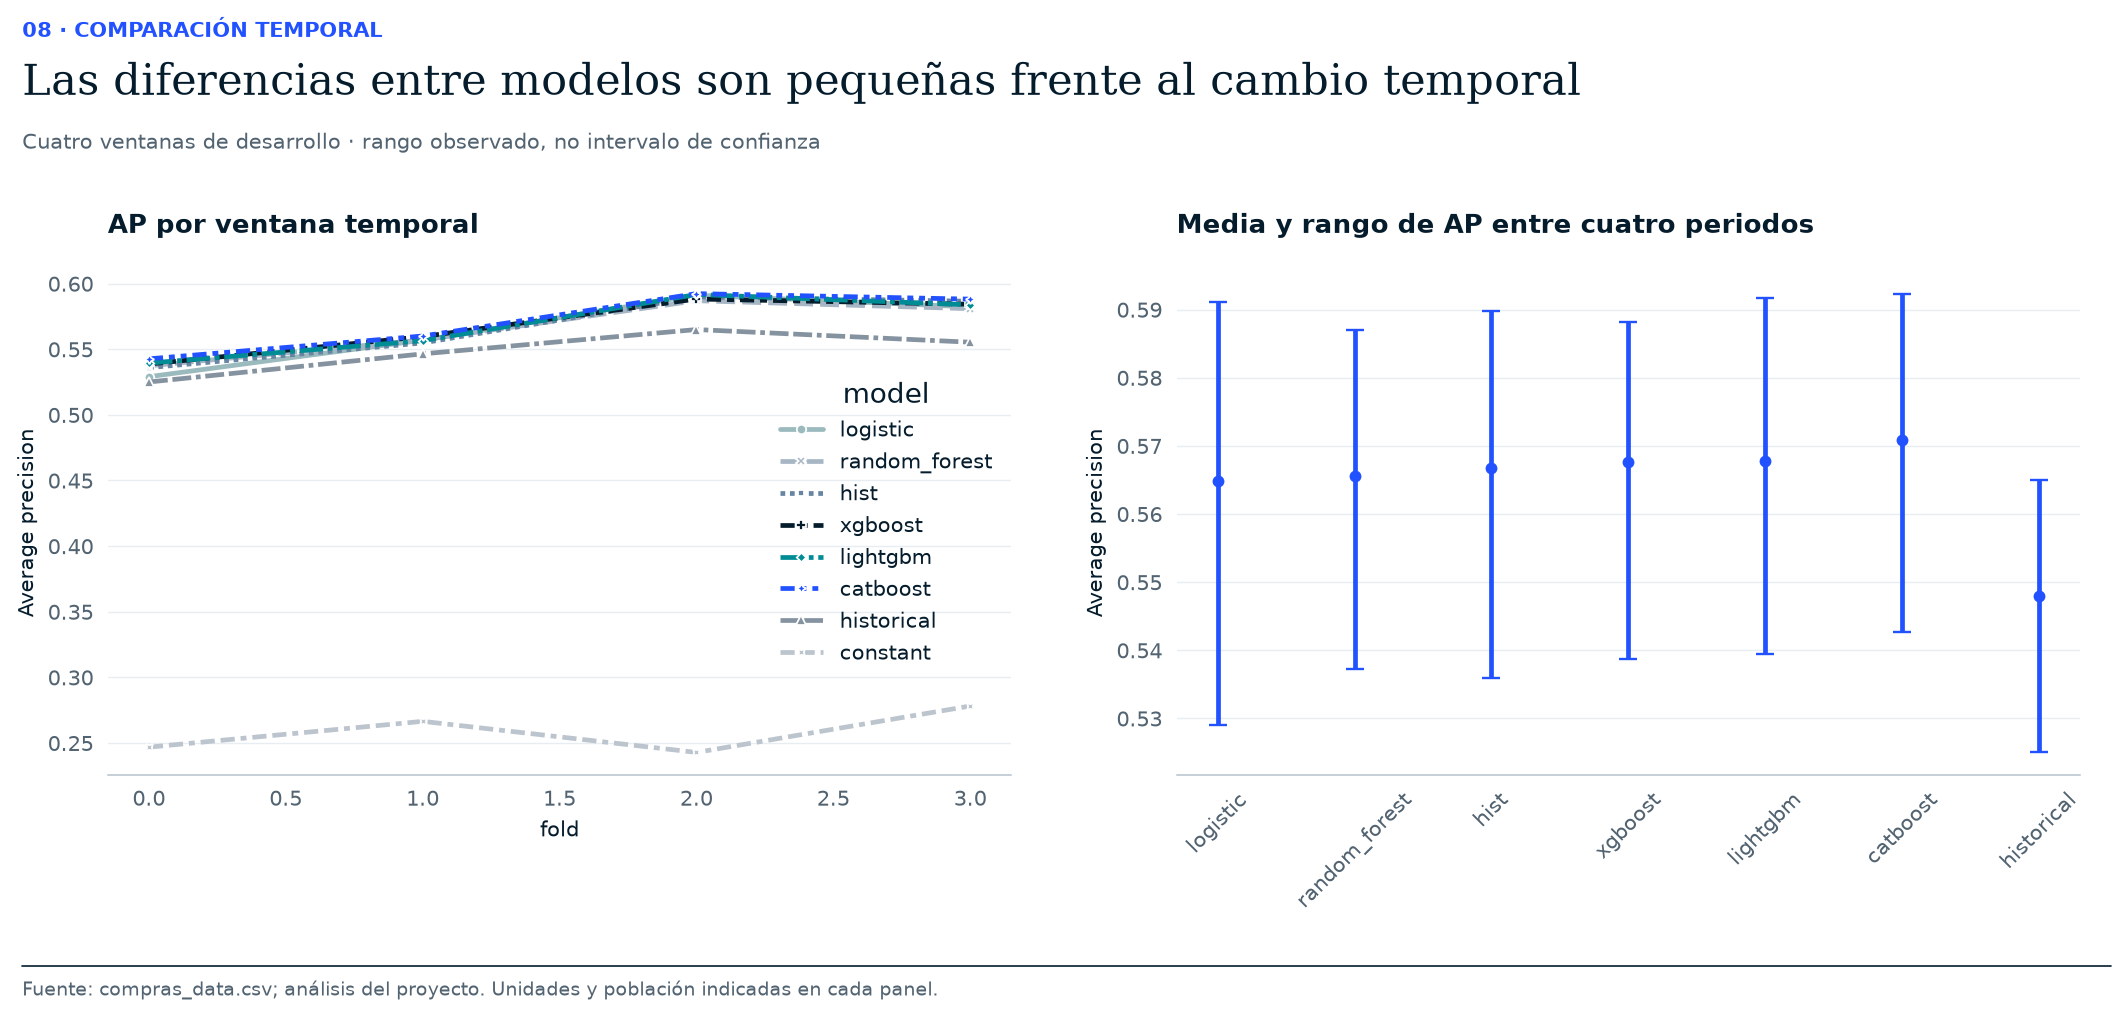

,model,fold,train_end,validation_end,ap,auc,brier,logloss,prevalencia,precision_5,recall_5,lift_5,precision_10,recall_10,lift_10,precision_20,recall_20,lift_20
0,catboost,0.000,296.000,392.000,0.559,0.737,0.162,0.498,0.266,0.764,0.144,2.868,0.706,0.265,2.651,0.590,0.443,2.215
1,catboost,0.000,392.000,488.000,0.596,0.771,0.144,0.453,0.243,0.873,0.180,3.596,0.721,0.297,2.971,0.593,0.489,2.443
2,catboost,0.000,488.000,584.000,0.592,0.748,0.164,0.502,0.278,0.868,0.156,3.122,0.706,0.254,2.537,0.607,0.436,2.181
3,lightgbm,0.000,296.000,392.000,0.546,0.729,0.165,0.505,0.266,0.756,0.142,2.838,0.696,0.261,2.611,0.579,0.435,2.172
4,lightgbm,0.000,392.000,488.000,0.593,0.773,0.144,0.454,0.243,0.841,0.174,3.463,0.727,0.300,2.993,0.593,0.489,2.443
5,lightgbm,0.000,488.000,584.000,0.587,0.743,0.165,0.506,0.278,0.847,0.152,3.045,0.712,0.256,2.561,0.605,0.435,2.174


In [4]:
from ferreyros_propension.plotting import evaluation_figures

predictions = pd.read_csv(OUTPUT / "tables/test_predictions.csv")
evaluation_figures(pd.concat([cv, baselines]), predictions, OUTPUT / "figures")
display(Image(filename=str(OUTPUT / "figures/08_validacion.png")))
display(style_table(pd.read_csv(OUTPUT / "tables/nested.csv")))

## 3. Robustez, calibración y límites de selección
El diagnóstico anidado vuelve a optimizar dos familias finalistas con cinco trials internos por ventana. Las familias se eligieron después de ver los folds externos en la búsqueda principal: por eso este diagnóstico **no elimina todo sesgo de selección**. Los cinco trials internos tampoco equivalen al presupuesto principal.

La calibración sigmoide se ajusta con OOF de los dos primeros periodos y se compara en los dos siguientes. Si mejora log loss, se reajusta sobre todo el OOF antes del benchmark. El diagnóstico sigue condicionado a la selección de modelo en desarrollo.

Las ablaciones retiran grupos sin retuning para medir sensibilidad, no probar que un grupo es inútil en cualquier modelo. La incertidumbre del benchmark se estima mediante bootstrap emparejado de clientes; no recoge todos los cambios posibles de calendario.

In [5]:
display(style_table(pd.read_csv(OUTPUT / "tables/calibration_selection.csv")))
display(style_table(pd.read_csv(OUTPUT / "tables/ablations.csv")))
display(style_table(pd.Series(json.loads((OUTPUT / "uncertainty.json").read_text()))))
bundle = joblib.load(OUTPUT / "model.joblib")
print(
    "Familia seleccionada:",
    bundle["family"],
    "Calibrada:",
    bundle["calibrator"] is not None,
)

,variant,ap,auc,brier,logloss,prevalencia,precision_5,recall_5,lift_5,precision_10,recall_10,lift_10,precision_20,recall_20,lift_20
0,raw,0.590,0.758,0.154,0.478,0.260,0.850,0.163,3.264,0.724,0.278,2.779,0.596,0.457,2.287
1,sigmoid,0.590,0.758,0.154,0.479,0.260,0.850,0.163,3.264,0.724,0.278,2.779,0.596,0.457,2.287


,removed,ap,brier
0,demografia,0.569,0.156
1,comercial,0.566,0.157
2,historial,0.424,0.181


,0
delta_ap,0.034
ci_low,0.023
ci_high,0.045
bootstrap,300.000


Familia seleccionada: catboost Calibrada: False


## 4. Benchmark final previamente consultado
Las métricas de este periodo se reportan como evidencia temporal histórica. No se vuelven a seleccionar parámetros a partir de ellas. Una estimación externa realmente nueva requiere nuevas observaciones.

La curva de calibración muestra sobreestimación en scores altos del benchmark, aun cuando Brier mejora respecto de la referencia histórica. Rechazar el calibrador en desarrollo no garantiza calibración perfecta en un periodo futuro; hay cambio temporal que debe vigilarse.

model,catboost,historical,constant
ap,0.4924,0.4581,0.2501
auc,0.7156,0.6734,0.5000
brier,0.1678,0.1698,0.1876
logloss,0.5119,0.5217,0.5625
precision_20,0.5096,0.4768,0.2501
recall_20,0.4076,0.3814,0.2001
lift_20,2.0375,1.9064,1.0000


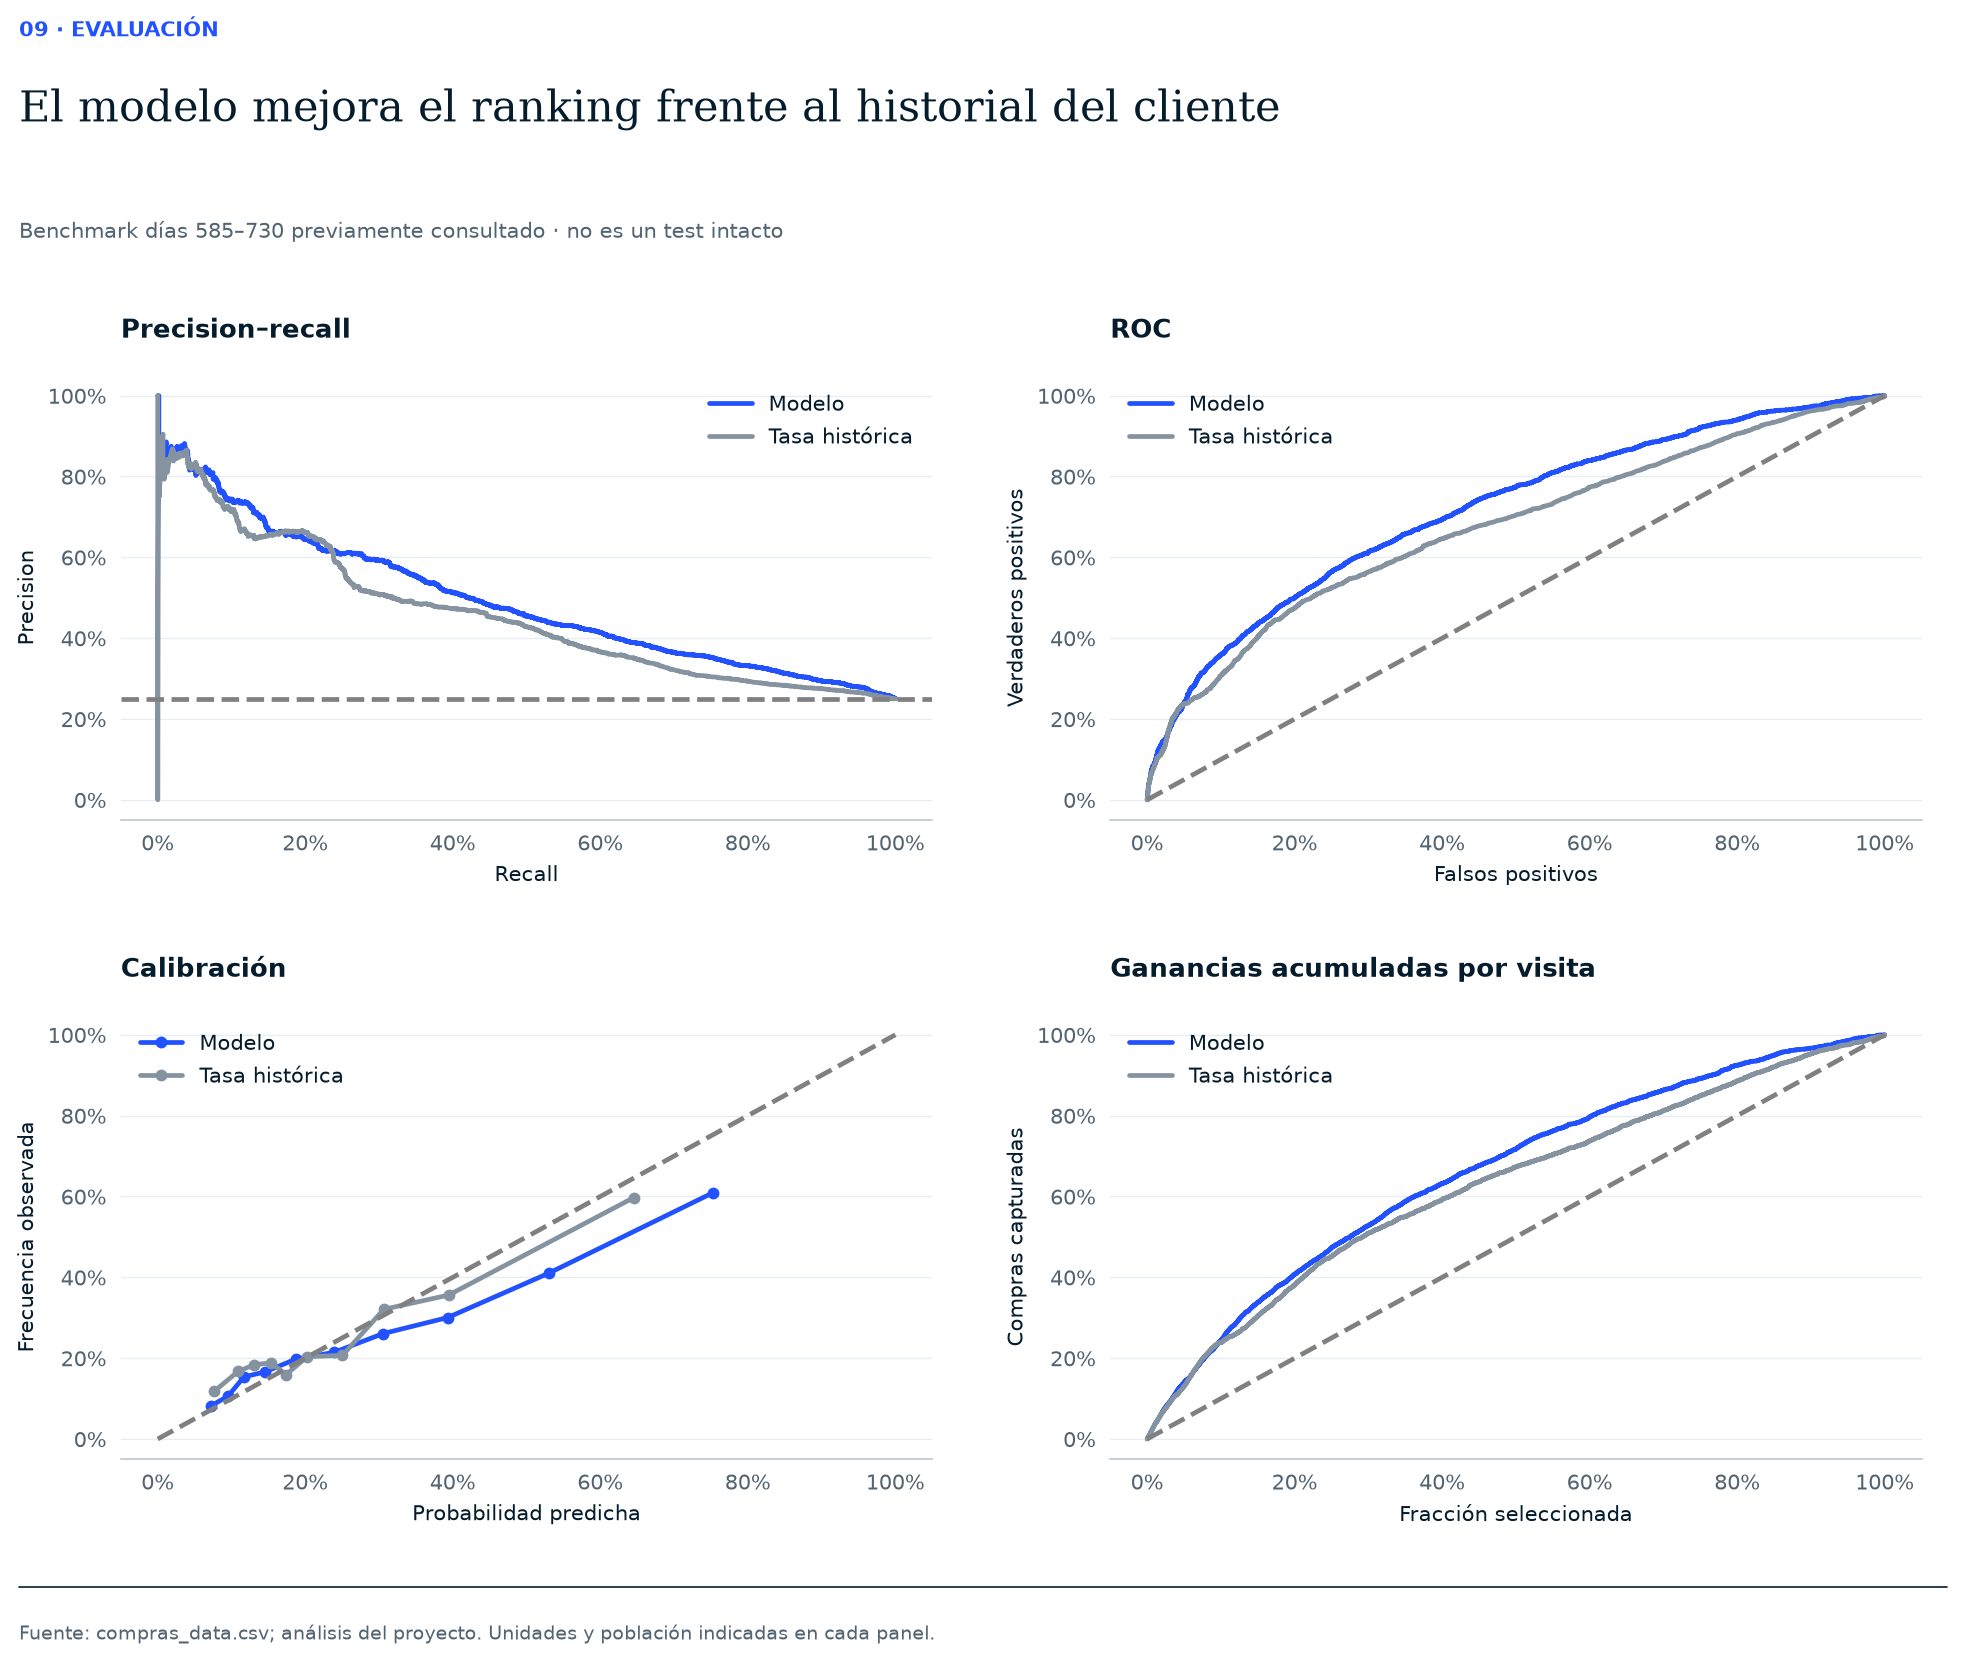

**Resultado:** AP 0.492, ROC AUC 0.716; el top 20% de visitas tiene precisión 51.0% y lift 2.04. Son compras observadas, no ventas incrementales.

,0
seleccionadas,2192.000
fraccion_real,0.205
precision,0.472
recall,0.387
lift,1.886


In [6]:
test_metrics = pd.read_csv(OUTPUT / "tables/test_metrics.csv")
display(
    style_table(
        test_metrics.set_index("model")[
            ["ap", "auc", "brier", "logloss", "precision_20", "recall_20", "lift_20"]
        ].T.style.format("{:.4f}")
    )
)
display(Image(filename=str(OUTPUT / "figures/09_evaluacion.png")))
selected = test_metrics.iloc[0]
display(
    Markdown(
        f"**Resultado:** AP {selected.ap:.3f}, ROC AUC {selected.auc:.3f}; el top 20% de visitas tiene precisión {selected.precision_20:.1%} y lift {selected.lift_20:.2f}. Son compras observadas, no ventas incrementales."
    )
)
display(
    style_table(pd.Series(json.loads((OUTPUT / "daily_capacity.json").read_text())))
)

In [7]:
# Sensibilidad a semilla: diagnóstico en desarrollo, sin elegir por benchmark.
from ferreyros_propension.modeling import cross_validate

seed_path = OUTPUT / "tables/seed_sensitivity.csv"
if not seed_path.exists():
    seed_rows = []
    for seed in [17, 73]:
        seed_config = {**config, "seed": seed}
        seed_metrics, _ = cross_validate(
            bundle["family"],
            bundle["params"],
            events,
            predictors,
            config["folds"],
            seed_config,
        )
        seed_metrics["seed"] = seed
        seed_rows.append(seed_metrics)
    pd.concat(seed_rows).to_csv(seed_path, index=False)
display(style_table(pd.read_csv(seed_path).groupby("seed").ap.agg(["mean", "std"])))

C:\Users\errop\OneDrive\Documentos\Projects\ferreyros-propension\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/11/15 21:52:41 INFO mlflow.agent.hint: Load the `mlflow-trace-instrumentation` skill at C:\Users\errop\OneDrive\Documentos\Projects\ferreyros-propension\.venv\Lib\site-packages\mlflow\assistant\skills\mlflow-trace-instrumentation\SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


,mean,std
seed,,
17,0.568,0.024
73,0.568,0.024


## 5. Explicabilidad del estimador base
SHAP explica dependencia del modelo, no efectos causales. La calibración posterior es una transformación adicional y no está atribuida por estos gráficos. Muestra aleatoria reproducible del benchmark; ejemplos locales elegidos por score alto, bajo y mediano, sin seleccionar solo aciertos favorables.

{'output_space': 'log_odds',
 'sample_size': 400,
 'top_features': ['tasa_previa',
  'precio_marca_5',
  'compras_30',
  'tasa_90',
  'tasa_30'],
 'explains': 'base_estimator_before_calibration'}

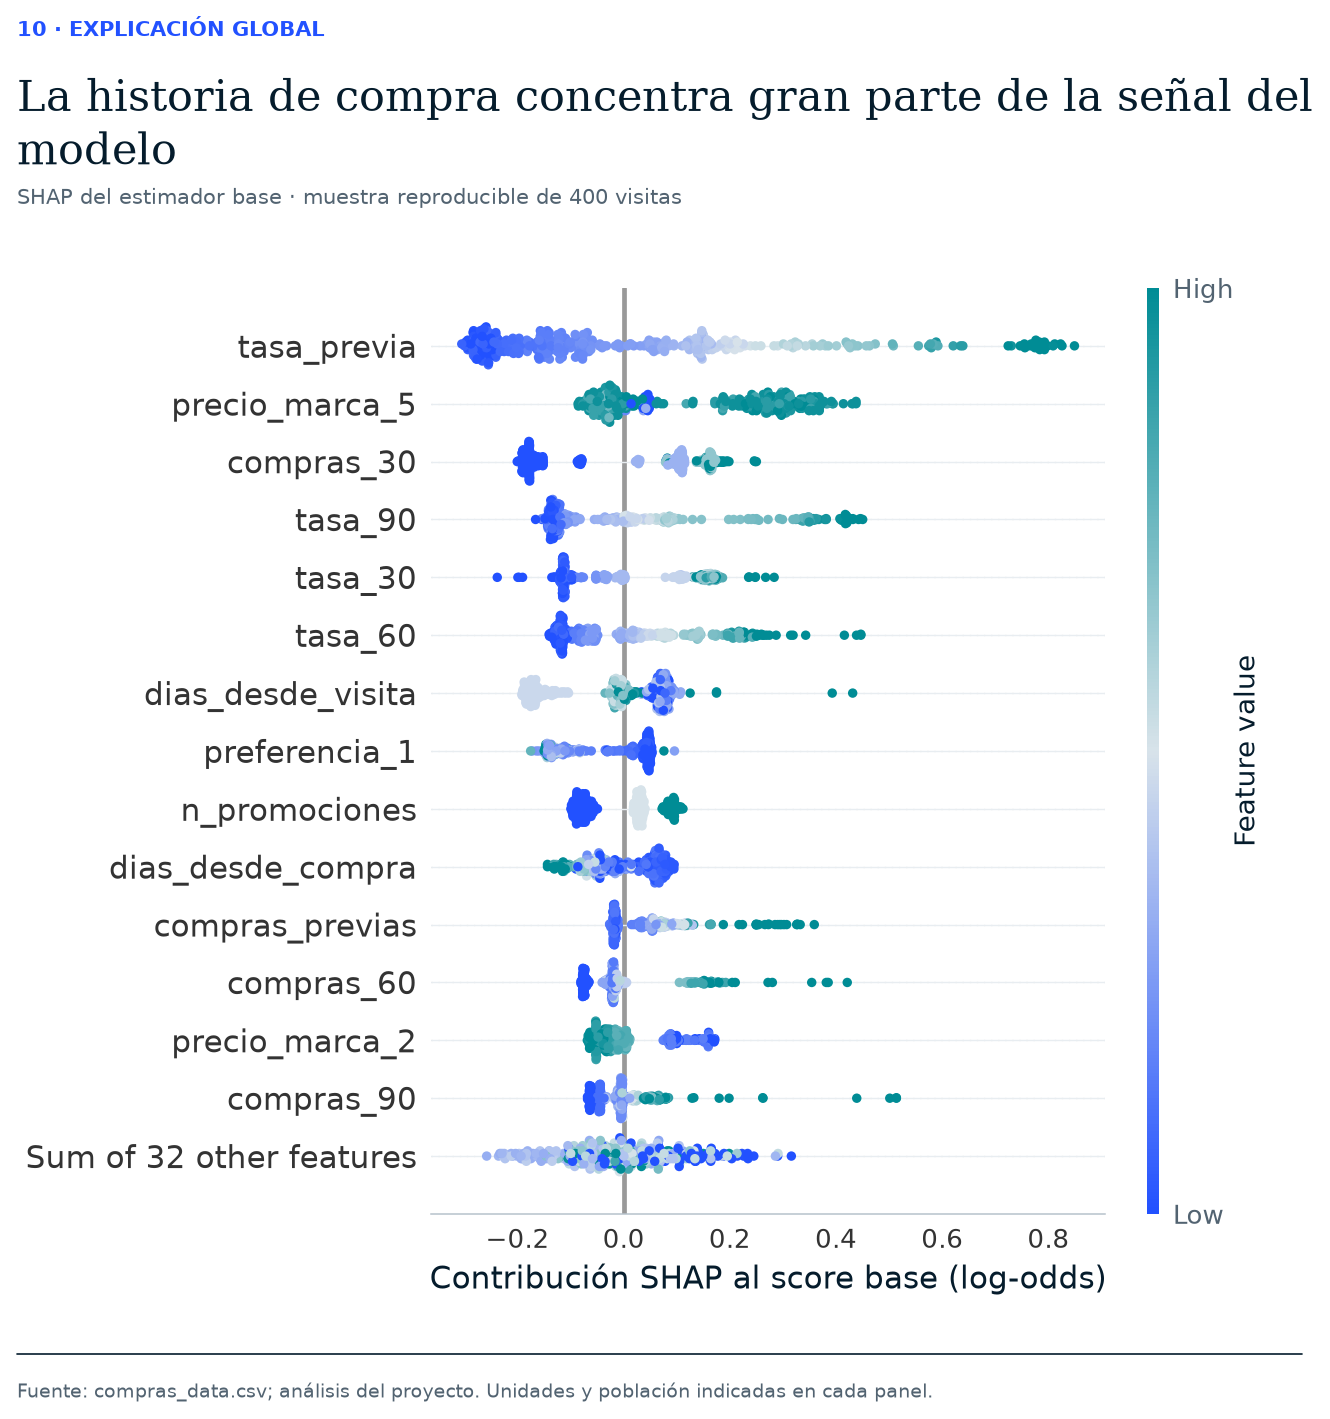

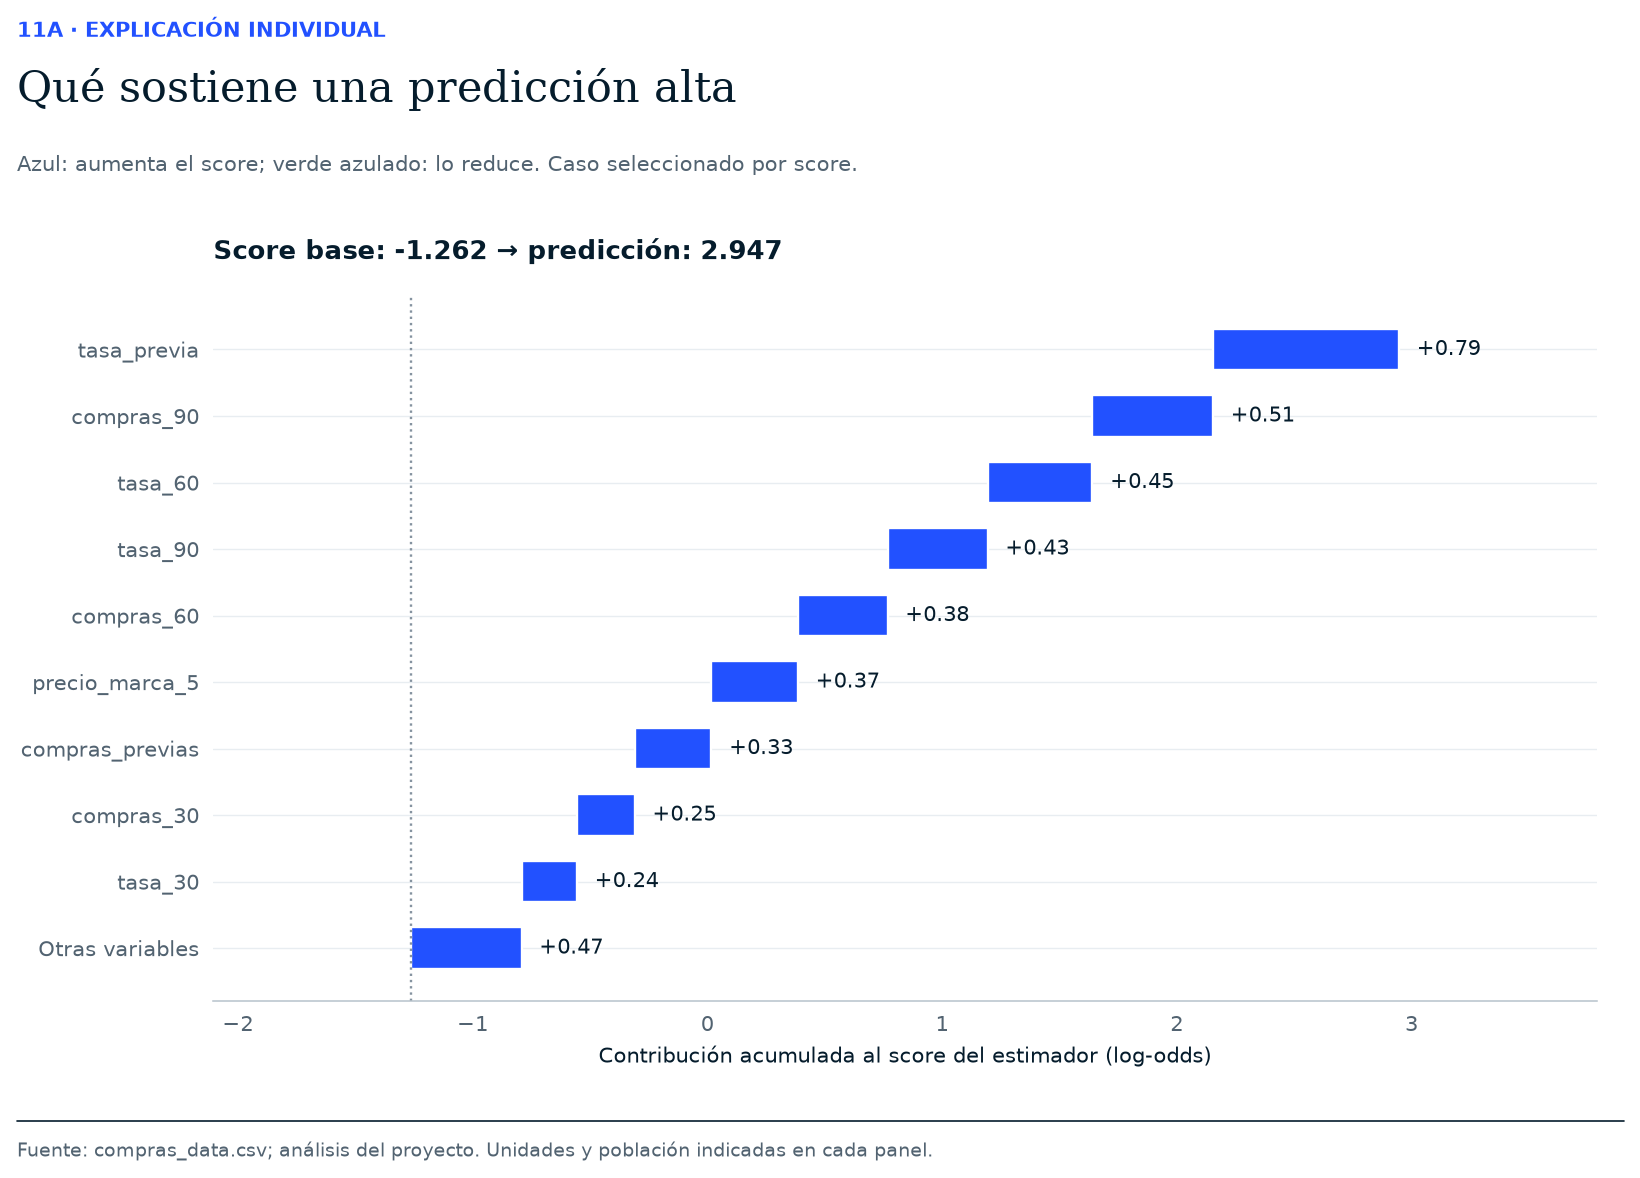

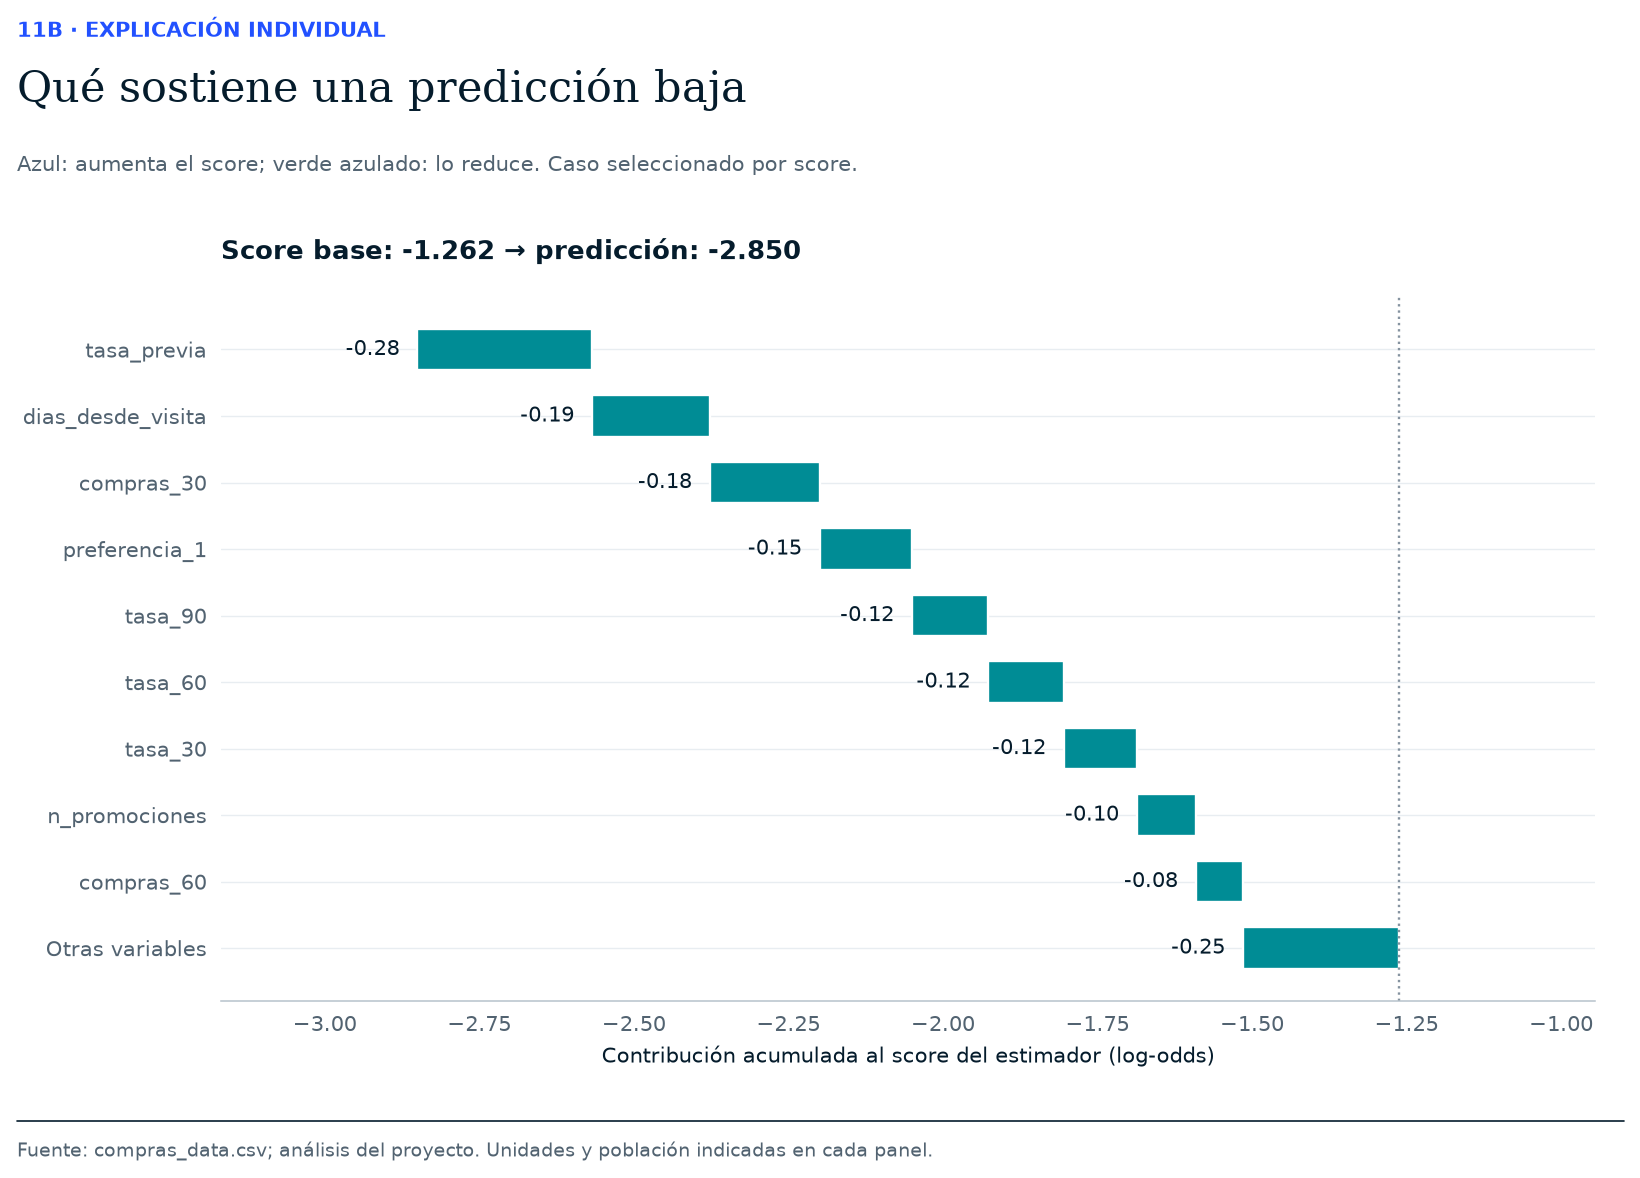

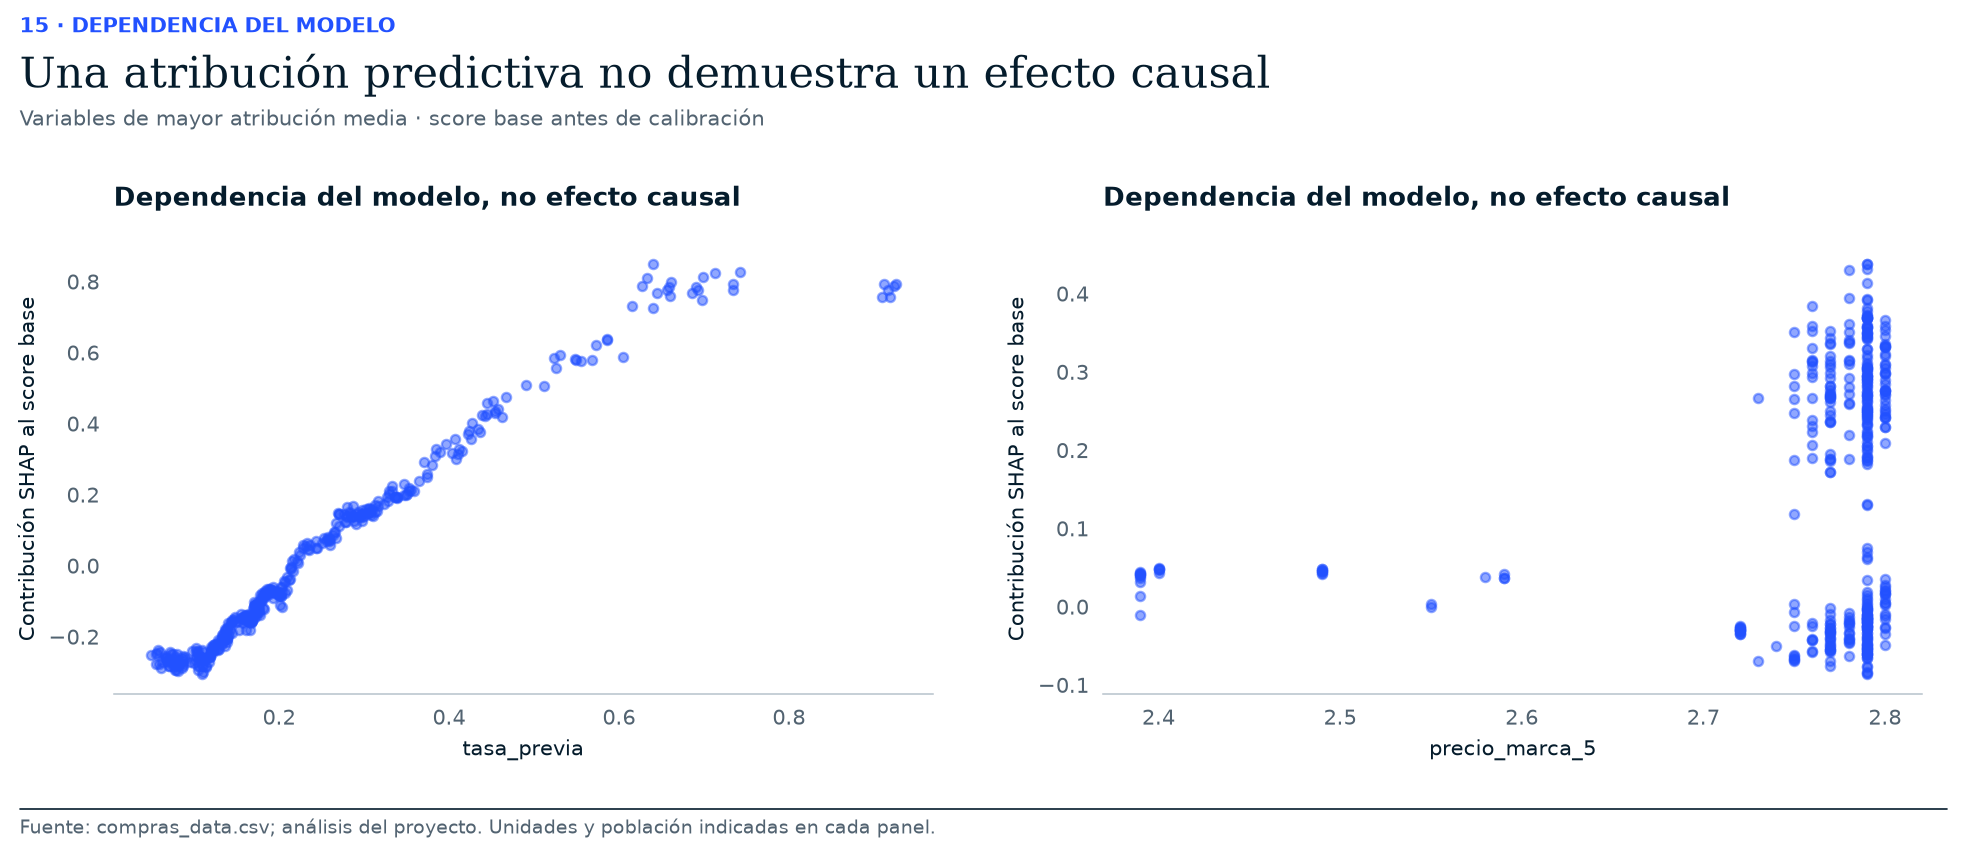

**Lectura:** las variables con mayor atribución media son tasa_previa, precio_marca_5, compras_30. Las relaciones pueden ser no lineales y dependen de las demás variables; no estiman el efecto de intervenir precios o promociones.

In [8]:
from ferreyros_propension.evaluation import explain_model

benchmark_mask = events.dia_visita.gt(config["development_end"])
explanation_metadata = explain_model(
    bundle, predictors.loc[benchmark_mask, bundle["columns"]], OUTPUT
)
display(explanation_metadata)
display(Image(filename=str(OUTPUT / "figures/10_shap_global.png")))
display(Image(filename=str(OUTPUT / "figures/11_shap_alta.png")))
display(Image(filename=str(OUTPUT / "figures/11_shap_baja.png")))
display(Image(filename=str(OUTPUT / "figures/15_shap_dependence.png")))
display(
    Markdown(
        "**Lectura:** las variables con mayor atribución media son "
        + ", ".join(explanation_metadata["top_features"][:3])
        + ". Las relaciones pueden ser no lineales y dependen de las demás variables; no estiman el efecto de intervenir precios o promociones."
    )
)

In [9]:
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

sample_indices = predictors.loc[benchmark_mask].sample(500, random_state=42).index
with threadpool_limits(limits=config["threads"]):
    importance = permutation_importance(
        bundle["model"],
        predictors.loc[sample_indices],
        events.loc[sample_indices, "incidencia_compra"],
        scoring="average_precision",
        n_repeats=3,
        random_state=42,
    )
importance_table = pd.DataFrame(
    {
        "variable": predictors.columns,
        "ap_loss": importance.importances_mean,
        "std": importance.importances_std,
    }
).sort_values("ap_loss", ascending=False)
display(style_table(importance_table.head(12)))
importance_table.to_csv(OUTPUT / "tables/permutation_importance.csv", index=False)

,variable,ap_loss,std
18,tasa_previa,0.035,0.003
32,tasa_90,0.013,0.006
1,precio_marca_2,0.007,0.001
19,dias_desde_visita,0.005,0.002
29,tasa_60,0.005,0.007
34,preferencia_2,0.004,0.002
42,precio_relativo_2,0.003,0.002
38,precio_min,0.003,0.002
0,precio_marca_1,0.002,0.002
20,marca_previa,0.002,0.000


## 6. Errores y segmentos
Comparar cobertura, score medio y error de probabilidad por edad, historial y tiempo. Grupos pequeños son diagnósticos, no conclusiones universales. No afirmamos generalización a clientes nuevos si el benchmark no contiene suficientes casos.

,visitas,clientes,conversion,score,brier
edad_grupo,,,,,
"(17, 29]",2695,129,0.223,0.240,0.160
"(29, 39]",3676,171,0.255,0.291,0.169
"(39, 49]",2256,105,0.242,0.270,0.164
"(49, 59]",1164,52,0.313,0.370,0.179
"(59, 80]",880,43,0.251,0.310,0.181


,visitas,clientes,conversion,score,brier
historial,,,,,
"(20.0, 60.0]",8,3,0.500,0.446,0.215
"(60.0, inf]",10663,500,0.250,0.284,0.168


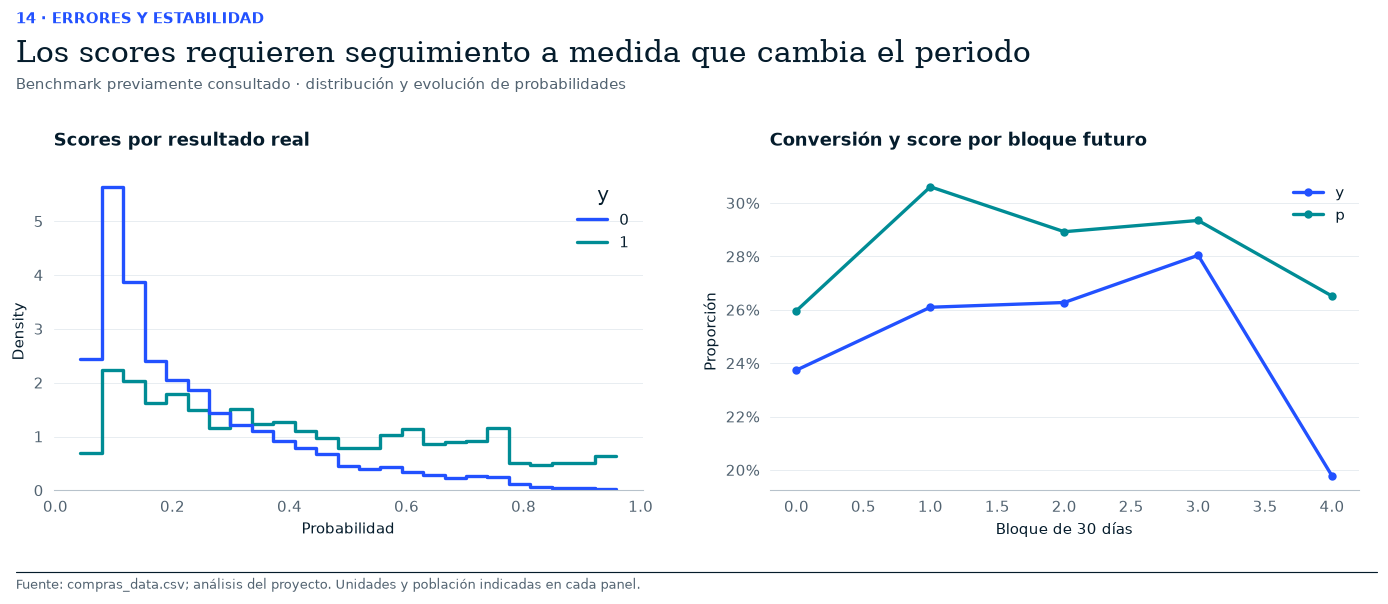

,id,dia_visita,y,p,visitas_previas,error_absoluto
3910,200000187,620,0,0.955,325,0.955
4020,200000191,649,1,0.049,95,0.951
3913,200000187,624,0,0.951,328,0.951
824,200000041,624,0,0.949,326,0.949
5146,200000247,624,0,0.948,319,0.948
9765,200000462,648,1,0.055,109,0.945
5732,200000273,701,1,0.059,112,0.941
4478,200000213,701,1,0.059,110,0.941


In [10]:
segmented = predictions.merge(
    events[["id", "dia_visita", "edad", "visitas_previas"]],
    on=["id", "dia_visita"],
    validate="one_to_one",
)
segmented["edad_grupo"] = pd.cut(segmented.edad, [17, 29, 39, 49, 59, 80])
segmented["historial"] = pd.cut(segmented.visitas_previas, [-1, 0, 20, 60, np.inf])
segmented["error_cuadrado"] = (segmented.y - segmented.p) ** 2
for column in ["edad_grupo", "historial"]:
    display(
        style_table(
            segmented.groupby(column, observed=True).agg(
                visitas=("y", "size"),
                clientes=("id", "nunique"),
                conversion=("y", "mean"),
                score=("p", "mean"),
                brier=("error_cuadrado", "mean"),
            )
        )
    )
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
import seaborn as sns

sns.histplot(
    data=segmented,
    x="p",
    hue="y",
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    fill=False,
    ax=axes[0],
)
axes[0].set(title="Scores por resultado real", xlabel="Probabilidad")
segmented.assign(periodo=(segmented.dia_visita - 585) // 30).groupby("periodo")[
    ["y", "p"]
].mean().plot(marker="o", ax=axes[1])
axes[1].set(
    title="Conversión y score por bloque futuro",
    ylabel="Proporción",
    xlabel="Bloque de 30 días",
)
save(figure, OUTPUT / "figures", "14_errores", close=False)
plt.show()
error_examples = segmented.assign(
    error_absoluto=(segmented.y - segmented.p).abs()
).nlargest(8, "error_absoluto")
display(
    style_table(
        error_examples[
            ["id", "dia_visita", "y", "p", "visitas_previas", "error_absoluto"]
        ]
    )
)

## 7. Uso comercial, captura de valor y límites
**Acción propuesta:** priorizar atención entre visitantes con presupuesto limitado. El top de visitas no equivale a clientes únicos; las campañas por cliente necesitan deduplicación y cadencia. La evaluación diaria tiene redondeo de cupos y reporta fracción real seleccionada.

**Medición de impacto:** piloto aleatorizado por cliente entre política propuesta y práctica actual, con presupuesto comparable. Definir efecto mínimo detectable y tamaño antes de ejecutar. Indicadores: margen neto incremental, conversión incremental, costo por compra incremental, adopción y cobertura. El ranking no identifica quién cambiará de conducta por recibir una oferta.

**Escenario editable, no ROI observado:**

`valor neto = clientes tratados × incremento causal de conversión × margen por compra − costo de atención − descuentos adicionales`.

Ventas usaría prioridades; marketing podría probar intervenciones; operaciones debe validar capacidad. Faltan costos, margen y efecto causal: no prometemos rentabilidad.

**Operación:** scoring batch por día con historia estrictamente previa, versión de modelo y mismas variables. Monitorear esquema, frescura, scores y desempeño cuando maduren etiquetas. Ante fallo volver a la práctica comercial actual. No hay API, despliegue cloud ni monitoreo automatizado implementados.

In [11]:
from ferreyros_propension.data import score_visits

scoring_day = 600
history = raw.loc[raw.dia_visita.lt(scoring_day)]
visits = raw.loc[raw.dia_visita.eq(scoring_day)].drop(
    columns=["incidencia_compra", "id_marca", "cantidad"]
)
scored = score_visits(bundle, history, visits)
display(style_table(scored.head(10)))
# Persistencia e inferencia deben coincidir con el benchmark del mismo día.
expected = predictions.loc[predictions.dia_visita.eq(scoring_day), ["id", "p"]]
joined = scored.merge(expected, on="id", validate="one_to_one")
np.testing.assert_allclose(joined.probabilidad, joined.p, atol=1e-8)
print("Scoring y predicciones guardadas coinciden.")

,id,dia_visita,probabilidad,version
156,200000002,600,0.096,20ca652a0599
778,200000010,600,0.082,20ca652a0599
1228,200000015,600,0.074,20ca652a0599
1625,200000019,600,0.143,20ca652a0599
2242,200000026,600,0.080,20ca652a0599
2818,200000032,600,0.060,20ca652a0599
2911,200000033,600,0.668,20ca652a0599
4774,200000050,600,0.106,20ca652a0599
6909,200000072,600,0.238,20ca652a0599
7271,200000076,600,0.093,20ca652a0599


Scoring y predicciones guardadas coinciden.


## 8. Qué se completó y qué sigue abierto
Se implementan EDA, preparación, búsqueda de seis familias, validación temporal, calibración condicional, ablaciones, diagnóstico anidado, incertidumbre, explicación, scoring y pruebas. No se usó GPU ni se generaron PDF, slides o TXT finales.

El presupuesto es acotado; no garantiza un óptimo. No se entrenó un ensemble porque la prioridad es validar primero candidatos individuales y no sumar complejidad sin evidencia independiente. Selección de características/hipótesis y familias usó la base de desarrollo: los diagnósticos no deben venderse como validación prospectiva nueva.

Revisar con el usuario: definición de categoría/producto, moneda/códigos, disponibilidad de información al scoring, política comercial y evidencia necesaria para promover el modelo.

Fuentes: [Optuna](https://optuna.readthedocs.io/en/stable/), [MLflow](https://mlflow.org/docs/latest/ml/tracking/), [scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html), [XGBoost](https://xgboost.readthedocs.io/en/stable/), [LightGBM](https://lightgbm.readthedocs.io/en/stable/), [CatBoost](https://catboost.ai/docs/), [SHAP](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html).